## Sparse matrices

A sparse matrix stores only its nonzero entries. `spdiags` builds one from diagonals: here the second-difference matrix, $2$ on the diagonal and $-1$ beside it, which approximates $-d^2/dx^2$.

In [ ]:
n = 8; e = ones(n, 1);
T = spdiags([-e 2*e -e], -1:1, n, n);
full(T(1:4, 1:4))
fprintf('%d nonzeros of %d entries\n', nnz(T), numel(T))
B = full(T);
whos T B


ans =

     2    -1     0     0
    -1     2    -1     0
     0    -1     2    -1
     0     0    -1     2



22 nonzeros of 64 entries
  Name      Size            Bytes  Class     Attributes

  B         8x8               512  double    
  T         8x8               424  double    sparse



`sparse(i, j, v, m, n)` assembles a matrix from triples; entries with the same $(i, j)$ add up, as they do when finite elements are assembled.

In [ ]:
S = sparse([1 2 2 3 1], [1 2 2 3 1], [10 1 2 5 -4], 3, 3);
full(S)
[i, j, v] = find(S);
disp([i j v])


ans =

     6     0     0
     0     3     0
     0     0     5

     1     1     6
     2     2     3
     3     3     5


### The Laplacian on a grid

`kron` builds the 2-D Laplacian from the 1-D one, $L = I \otimes T + T \otimes I$, on an $n \times n$ grid of unknowns. `spy` shows where its nonzeros are: five diagonals, two of them $n$ away from the main one.

144 unknowns, 672 nonzeros (3.2% of the entries)


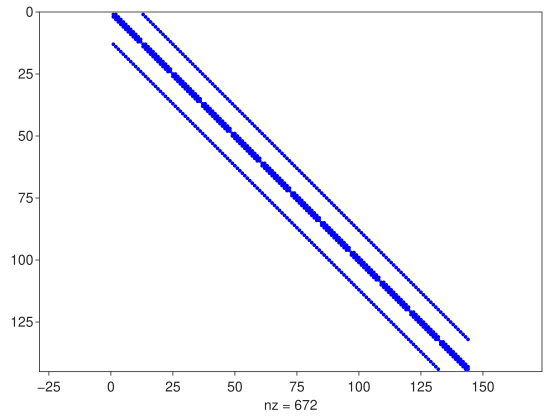

In [ ]:
n = 12; e = ones(n, 1);
T = spdiags([-e 2*e -e], -1:1, n, n);
I = speye(n);
L = kron(I, T) + kron(T, I);
fprintf('%d unknowns, %d nonzeros (%.1f%% of the entries)\n', size(L, 1), nnz(L), 100*nnz(L)/numel(L))
figure
spy(L)

`numgrid` numbers the points of a region and `delsq` builds its Laplacian directly; for the square it is the same matrix.

In [ ]:
G = numgrid('S', n + 2);
D = delsq(G);
fprintf('same matrix: %d\n', isequal(D, L))

same matrix: 1


### Solving Poisson's equation

$-\Delta u = 1$ on the unit square with $u = 0$ on the boundary becomes $L u = h^2 \mathbf{1}$. Backslash solves the sparse system directly.

largest value 0.073563 (the continuous problem: 0.073671)


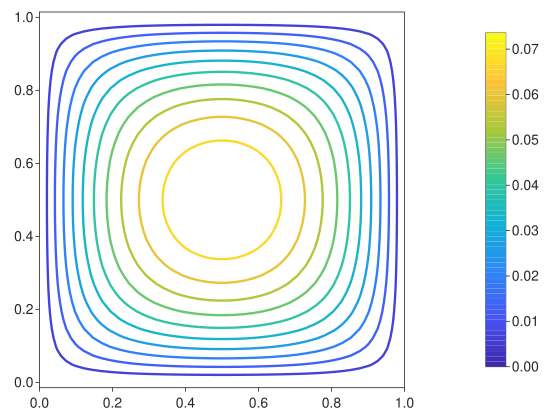

In [ ]:
n = 40; h = 1/(n + 1); e = ones(n, 1);
T = spdiags([-e 2*e -e], -1:1, n, n);
L = kron(speye(n), T) + kron(T, speye(n));
u = L \ (h^2 * ones(n^2, 1));
fprintf('largest value %.6f (the continuous problem: 0.073671)\n', max(u))
U = zeros(n + 2); U(2:end-1, 2:end-1) = reshape(u, n, n);   % with the boundary's zeros
[X, Y] = meshgrid(h*(0:n + 1));
figure
contour(X, Y, U, 10, 'LineWidth', 1.2), axis equal, colorbar

### Eigenvalues

`eigs` finds a few eigenvalues of a large sparse matrix. For the 1-D matrix they are known exactly: $\lambda_k = 2 - 2\cos\left(\frac{k\pi}{n+1}\right)$.

In [ ]:
n = 200; e = ones(n, 1);
T = spdiags([-e 2*e -e], -1:1, n, n);
lam = sort(eigs(T, 4, 'smallestabs'));
exact = 2 - 2*cos((1:4)'*pi/(n + 1));
fprintf('eigs %.10f   exact %.10f\n', [lam exact]')
fprintf('condition number estimate %.4g (exact %.4g)\n', condest(T), cond(full(T), 1))

eigs 0.0002442861   exact 0.0002442861
eigs 0.0009770848   exact 0.0009770848
eigs 0.0021982170   exact 0.0021982170
eigs 0.0039073845   exact 0.0039073845


condition number estimate 2.02e+04 (exact 2.02e+04)


### Conjugate gradients, by hand

For a symmetric positive definite system, conjugate gradients needs only products with the matrix, which are cheap when it is sparse. Each step minimizes the error in the $A$-norm over a growing Krylov space.

62 steps, difference from backslash 3.70e-13


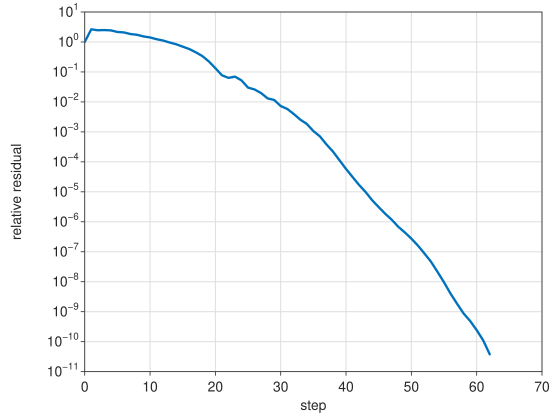

In [ ]:
n = 30; e = ones(n, 1);
T = spdiags([-e 2*e -e], -1:1, n, n);
A = kron(speye(n), T) + kron(T, speye(n));
b = ones(n^2, 1);
x = zeros(size(b)); r = b; p = r; rr = r'*r;
res = norm(r);
for k = 1:200
    Ap = A*p;
    alpha = rr / (p'*Ap);
    x = x + alpha*p;
    r = r - alpha*Ap;
    rrnew = r'*r;
    res(end + 1) = sqrt(rrnew);
    if res(end) < 1e-10 * res(1), break, end
    p = r + (rrnew/rr)*p;
    rr = rrnew;
end
fprintf('%d steps, difference from backslash %.2e\n', k, norm(x - A\b)/norm(A\b))
figure
semilogy(0:numel(res) - 1, res/res(1), 'LineWidth', 1.2), grid on
xlabel('step'), ylabel('relative residual')

*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*